### Comparison between SteadierCom and experimental results

In [28]:
import pandas as pd
import numpy as np
import json
import csv
import warnings
from os import listdir
import reframed

import libsbml
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp

In [29]:
import sys
sys.path.append("../functions/")
import compare_inter_exp_sim

In [30]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


#### Mapping names to seed ids (seem to have a good overlap)

Interactions were found in table (areaThreshold2.mat) from Guillen github repo: https://github.com/Mitchell-SysBio/2021_cellsystems/tree/v1.0.0

This was converted to csv in Matlab (../data/Guillen2021/Guillen_interaction.csv).

In [31]:
exp_interaction = pd.read_csv("../data/Guillen2021/Guillen_interaction.csv",index_col=0)

mutants = ["icd","cysW","panZ","panD","bioH","bioF","bioC"]

exp_interaction = exp_interaction.loc[exp_interaction.index.isin(mutants),exp_interaction.columns.isin(mutants)]
exp_interaction.index = exp_interaction.index.map(lambda x:"mutant_"+x)
exp_interaction.columns = exp_interaction.columns.map(lambda x:"mutant_"+x)
exp_interaction_ser = exp_interaction.stack()
exp_interaction_ser.index.names = ["receiver","donor"]
exp_interaction_ser.name = "experimental" 

**Load steadiercom results**

In [32]:
steadiercom_abundance = pd.read_csv("../output/Guillen2021/results_steadiercom/results_abundance/ecoli_mutants.tsv",sep="\t")

steadiercom_growth = pd.read_csv("../output/Guillen2021/results_steadiercom/results_growth/ecoli_mutants.tsv",sep="\t")

steadiercom_growth_abundance = pd.read_csv("../output/Guillen2021/results_steadiercom/results_growth_abundance/ecoli_mutants.tsv",sep="\t")

**Load smetana results**

In [33]:
smetana = pd.read_csv("../output/Guillen2021/smetana/_detailed.tsv",sep="\t")

**Load steadycom results**

In [34]:
steadycom_fixed_abundance = pd.read_csv("../output/Guillen2021/steadycom/fixed_abundance/cross_feeding.tsv",sep="\t")
steadycom = pd.read_csv("../output/Guillen2021/steadycom/no_abundance/cross_feeding.tsv",sep="\t")

**Process data**

In [35]:
steadiercom_dict = {
    "SteadierCom - Fixed growth":steadiercom_growth,
    "SteadierCom - Fixed growth & abundance":steadiercom_growth_abundance,
    "SteadierCom - Fixed abundance":steadiercom_abundance
}
steadiercom_dict_inter = {}

for name,simulated in steadiercom_dict.items():
    simulated = simulated[(simulated.donor!="environment") & (simulated.receiver!="environment")].copy()
    steadiercom_dict_inter[name]=simulated


steadiercom_dict_rec = {}
for name,simulated in steadiercom_dict.items():
    simulated = simulated[(simulated.receiver!="environment")].copy()
    steadiercom_dict_rec[name]=simulated


steadycom_dict = {
    "SteadyCom - Nothing fixed":steadycom,
    "SteadyCom - Fixed abundance":steadycom_fixed_abundance
}
steadycom_dict_inter = {}

for name,simulated in steadycom_dict.items():
    simulated = simulated.dropna().copy()
    steadycom_dict_inter[name]=simulated


steadycom_dict_rec = {}
for name,simulated in steadycom_dict.items():
    simulated = simulated.fillna("environment")
    simulated = simulated[(simulated.receiver!="environment")].copy()   
    steadycom_dict_rec[name]=simulated


## Cooperation - SteadierCom

#### SteadierCom - scatterplot - frequency count

[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())


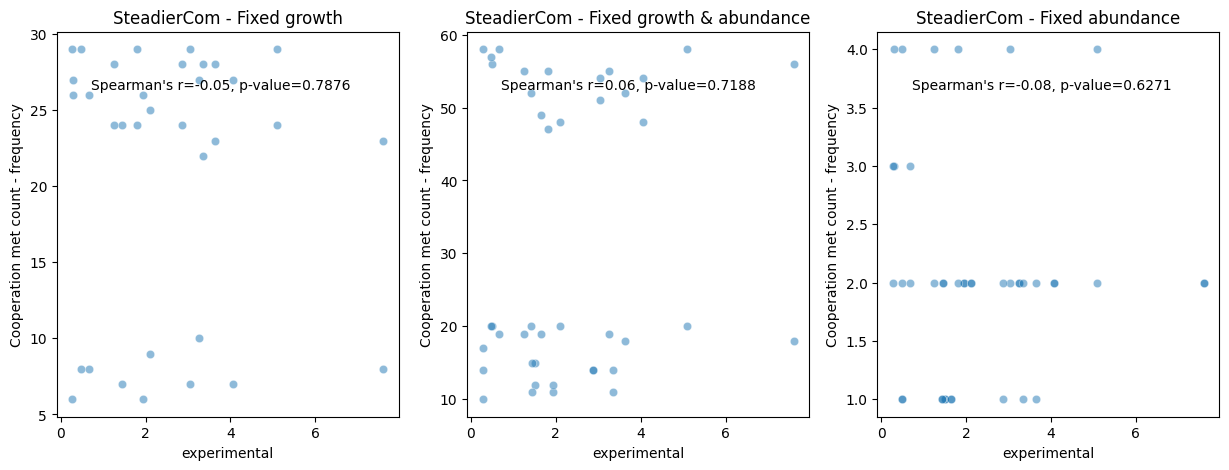

In [39]:
data_dict,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(steadiercom_dict_inter,
                                  exp_interaction_ser,
                                  coop_or_comp="coop",
                                  metric="frequency",
                                  sim_thresh =0.01,
                                  count_or_sum="count")

fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name,exp_sim_combined in data_dict.items():
    
    compare_inter_exp_sim.plot_coop_or_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

#### SteadierCom - scatterplot - rate count

[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())


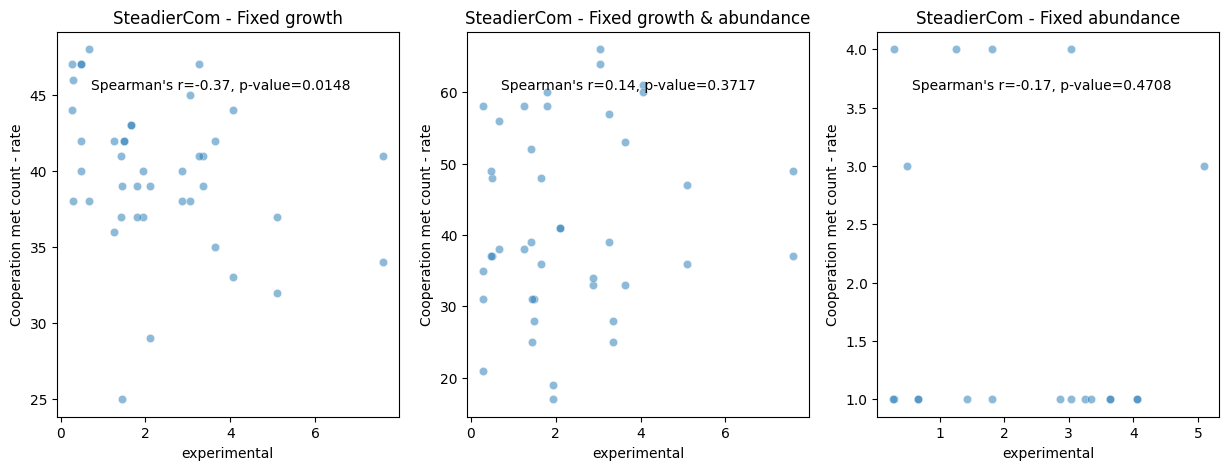

In [42]:
data_dict,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(steadiercom_dict_rec,
                                  exp_interaction_ser,
                                  coop_or_comp="coop",
                                  metric="rate",
                                  sim_thresh =1e-3,
                                  count_or_sum="count")

fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name,exp_sim_combined in data_dict.items():

    compare_inter_exp_sim.plot_coop_or_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

#### SteadyCom - scatterplot - rate count

[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())


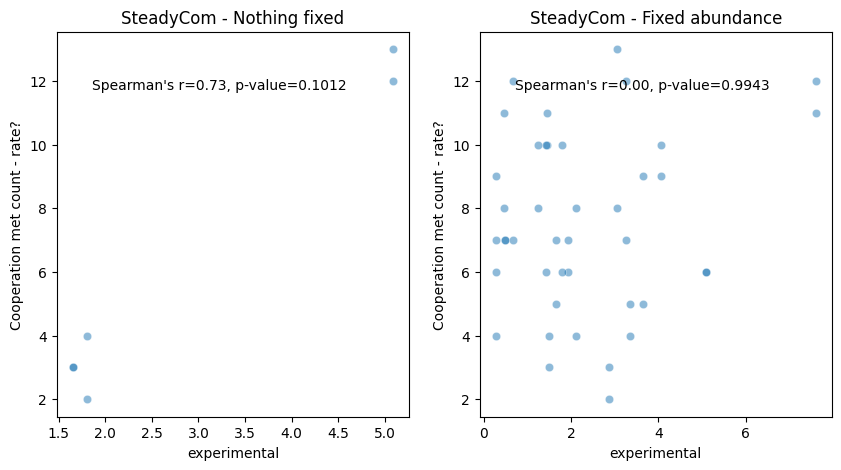

In [44]:
data_dict,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(steadycom_dict_inter,
                                  exp_interaction_ser,
                                  coop_or_comp="coop",
                                  metric="rate?",
                                  sim_thresh =1e-3,
                                  count_or_sum="count")

fig, axs = plt.subplots(1,2,figsize=(10,5))
i = 0
for name,exp_sim_combined in data_dict.items():

    compare_inter_exp_sim.plot_coop_or_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

### Competition and cooperation - combined

[INFO] 'plot_coop_comp_combined' filters data: receiver!=donor. Before combining coop and comp, we use fillna(0)
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_inter_exp_sim.py:224: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


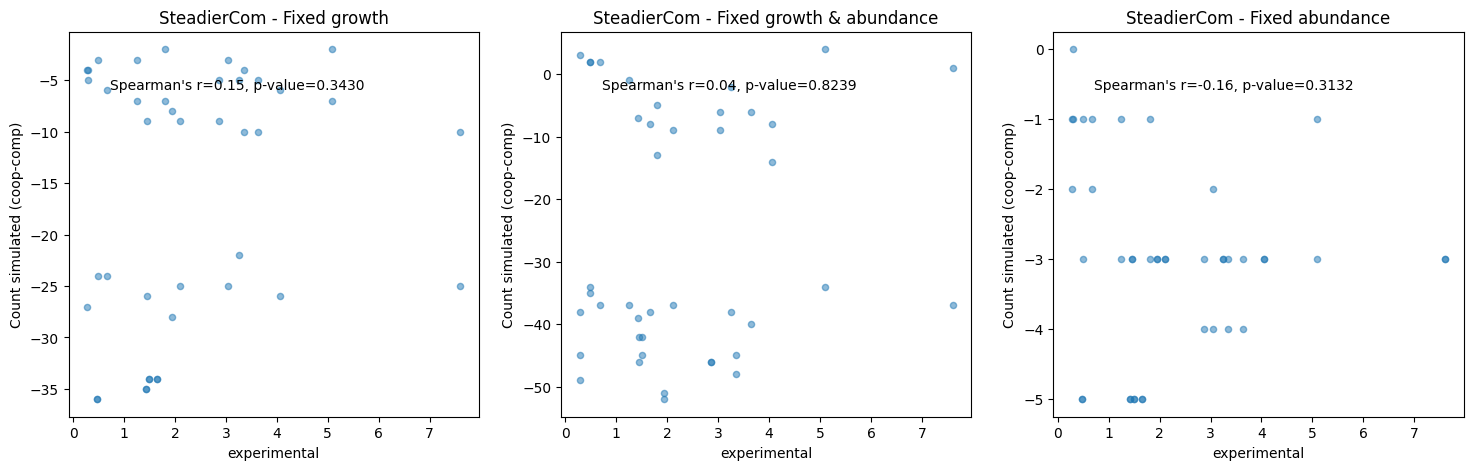

In [46]:
fig,axs = compare_inter_exp_sim.plot_coop_comp_combined(simulated_dict_rec=steadiercom_dict_rec,
                                              simulated_dict_inter=steadiercom_dict_inter,
                                              exp_ser=exp_interaction_ser,
                                              metric="frequency",
                                              count_or_sum="count",
                                              sim_thresh=0.01)

[INFO] 'plot_coop_comp_combined' filters data: receiver!=donor. Before combining coop and comp, we use fillna(0)
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_inter_exp_sim.py:224: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


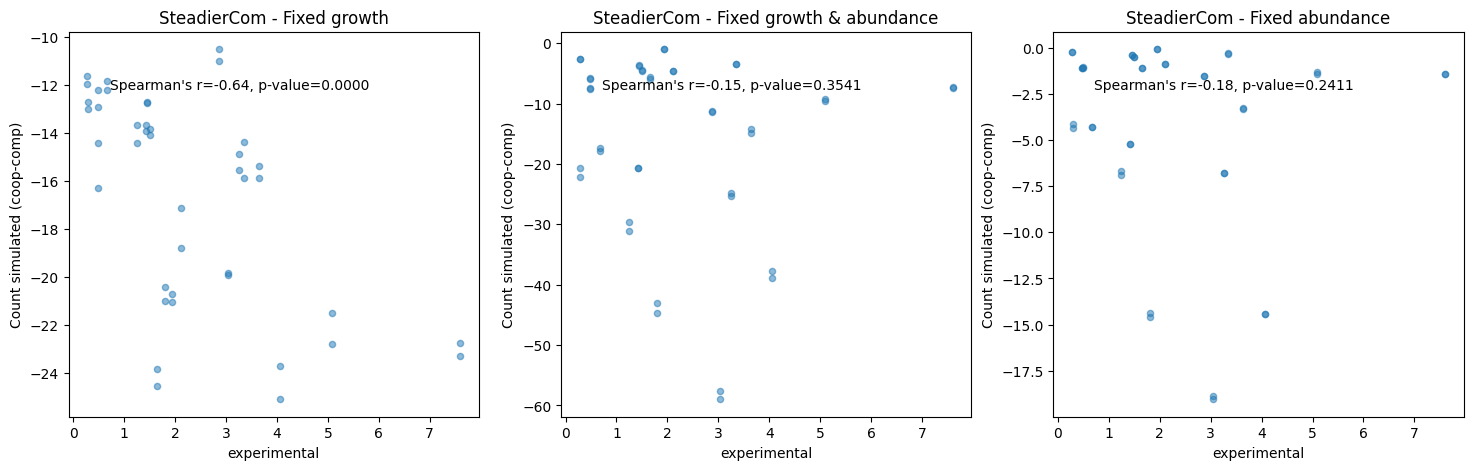

In [47]:
fig,axs = compare_inter_exp_sim.plot_coop_comp_combined(simulated_dict_rec=steadiercom_dict_rec,
                                              simulated_dict_inter=steadiercom_dict_inter,
                                              exp_ser=exp_interaction_ser,
                                              metric="rate",
                                              count_or_sum="sum",
                                              sim_thresh=False)




[INFO] 'plot_coop_comp_combined' filters data: receiver!=donor. Before combining coop and comp, we use fillna(0)
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_inter_exp_sim.py:224: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


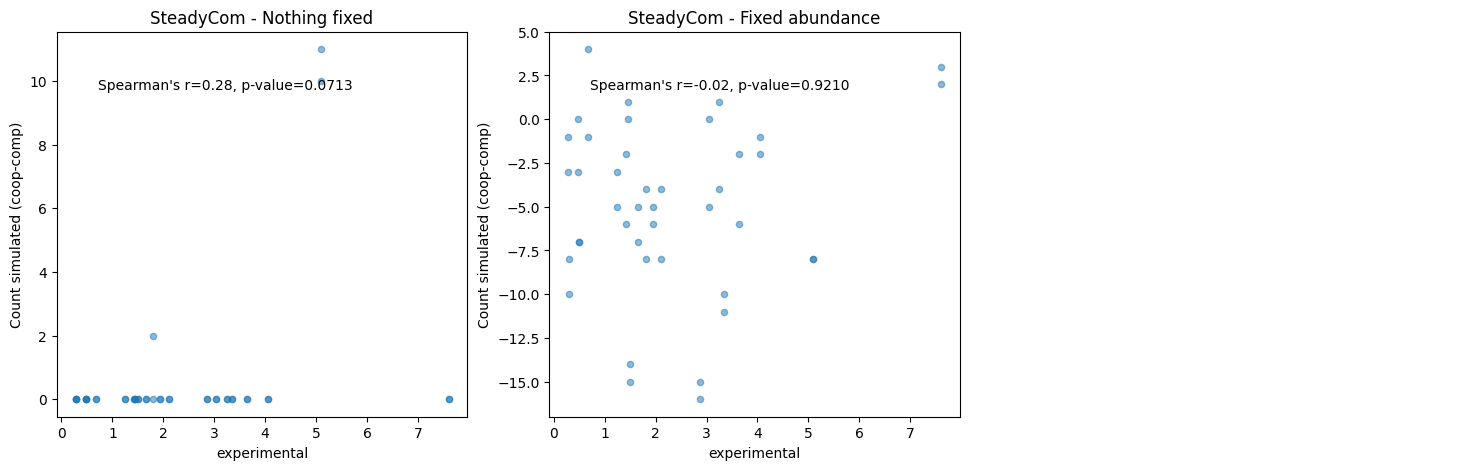

In [48]:
fig,axs = compare_inter_exp_sim.plot_coop_comp_combined(simulated_dict_rec=steadycom_dict_rec,
                                              simulated_dict_inter=steadycom_dict_inter,
                                              exp_ser=exp_interaction_ser,
                                              metric="rate?",
                                              count_or_sum="count",
                                              sim_thresh=1e-3)

axs[-1].set_axis_off()